In [1]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
zip_path = "/content/ml-latest-small.zip"
extract_path = "/content/"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

data_path = "/content/ml-latest-small"
movies = pd.read_csv(os.path.join(data_path, "movies.csv"))

print("Dataset downloaded successfully!")
print("Total movies:", len(movies))
movies.head()

Dataset downloaded successfully!
Total movies: 9742


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
print("Dataset shape:", movies.shape)
print("\nColumn names:")
print(movies.columns.tolist())

print("\nMissing values:")
print(movies.isnull().sum())

print("\nDuplicate rows:", movies.duplicated().sum())

print("\nSample movie records:")
display(movies.head(10))

Dataset shape: (9742, 3)

Column names:
['movieId', 'title', 'genres']

Missing values:
movieId    0
title      0
genres     0
dtype: int64

Duplicate rows: 0

Sample movie records:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


In [4]:
movies = movies.dropna(subset=["title", "genres"]).copy()
movies = movies.drop_duplicates(subset=["movieId"])

movies["genre_list"] = movies["genres"].apply(
    lambda x: [] if x == "(no genres listed)" else x.split("|")
)

print("Movies after cleaning:", len(movies))
display(movies[["title", "genres", "genre_list"]].head())

Movies after cleaning: 9742


,title,genres,genre_list
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,Jumanji (1995),Adventure|Children|Fantasy,"[Adventure, Children, Fantasy]"
2,Grumpier Old Men (1995),Comedy|Romance,"[Comedy, Romance]"
3,Waiting to Exhale (1995),Comedy|Drama|Romance,"[Comedy, Drama, Romance]"
4,Father of the Bride Part II (1995),Comedy,[Comedy]


In [5]:
mlb = MultiLabelBinarizer()

genre_features = mlb.fit_transform(movies["genre_list"])

genre_matrix = pd.DataFrame(
    genre_features,
    columns=mlb.classes_,
    index=movies.index
)

print("Total genre features:", len(mlb.classes_))
print("Feature matrix shape:", genre_matrix.shape)

display(genre_matrix.head())

Total genre features: 19
Feature matrix shape: (9742, 19)


,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

knn_model.fit(genre_features)

print("KNN model trained successfully!")

KNN model trained successfully!


In [7]:
def recommend_movies(movie_name, n_recommendations=10):
    movie_name = movie_name.strip().casefold()

    if not movie_name:
        print("Please enter a movie title.")
        return pd.DataFrame()

    titles = movies["title"].str.casefold()

    exact_matches = movies.index[titles == movie_name].tolist()

    if exact_matches:
        movie_idx = exact_matches[0]
    else:
        partial_matches = movies.index[
            titles.str.contains(movie_name, regex=False, na=False)
        ].tolist()

        if not partial_matches:
            print("Movie not found. Try another title.")
            return pd.DataFrame()

        if len(partial_matches) > 1:
            print("Multiple matches found. Choose one:")
            print(movies.loc[partial_matches, "title"].head(10).to_list())
            return pd.DataFrame()

        movie_idx = partial_matches[0]

    position = movies.index.get_loc(movie_idx)

    k = min(n_recommendations + 1, len(movies))

    distances, indices = knn_model.kneighbors(
        genre_features[position].reshape(1, -1),
        n_neighbors=k
    )

    recommendations = []

    for distance, neighbor_position in zip(
        distances[0], indices[0]
    ):
        if neighbor_position == position:
            continue

        movie_row = movies.iloc[neighbor_position]

        recommendations.append({
            "Movie Title": movie_row["title"],
            "Genres": movie_row["genres"],
            "Similarity (%)": round((1 - distance) * 100, 2)
        })

        if len(recommendations) >= n_recommendations:
            break

    return pd.DataFrame(recommendations)

In [8]:
recommendations = recommend_movies(
    "Toy Story (1995)",
    n_recommendations=10
)

display(recommendations)

,Movie Title,Genres,Similarity (%)
0,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,100.0
1,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,100.0
2,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,100.0
3,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,100.0
4,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,100.0
5,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,100.0
6,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,100.0
7,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,100.0
8,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,100.0
9,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,100.0


In [9]:
test_movies = [
    "Jumanji (1995)",
    "GoldenEye (1995)",
    "Heat (1995)"
]

for movie in test_movies:
    print(f"\nRecommendations for: {movie}")
    result = recommend_movies(movie, n_recommendations=5)
    display(result)


Recommendations for: Jumanji (1995)


,Movie Title,Genres,Similarity (%)
0,Gulliver's Travels (1996),Adventure|Children|Fantasy,100.0
1,Seventh Son (2014),Adventure|Children|Fantasy,100.0
2,Santa Claus: The Movie (1985),Adventure|Children|Fantasy,100.0
3,Pete's Dragon (2016),Adventure|Children|Fantasy,100.0
4,The Cave of the Golden Rose (1991),Adventure|Children|Fantasy,100.0



Recommendations for: GoldenEye (1995)


,Movie Title,Genres,Similarity (%)
0,Mission: Impossible - Fallout (2018),Action|Adventure|Thriller,100.0
1,Ffolkes (1979),Action|Adventure|Thriller,100.0
2,Tomorrow Never Dies (1997),Action|Adventure|Thriller,100.0
3,"Expendables, The (2010)",Action|Adventure|Thriller,100.0
4,Anaconda (1997),Action|Adventure|Thriller,100.0



Recommendations for: Heat (1995)


,Movie Title,Genres,Similarity (%)
0,Dirty Harry (1971),Action|Crime|Thriller,100.0
1,SuperFly (2018),Action|Crime|Thriller,100.0
2,Judgment Night (1993),Action|Crime|Thriller,100.0
3,Kill Bill: Vol. 1 (2003),Action|Crime|Thriller,100.0
4,Taken 3 (2015),Action|Crime|Thriller,100.0


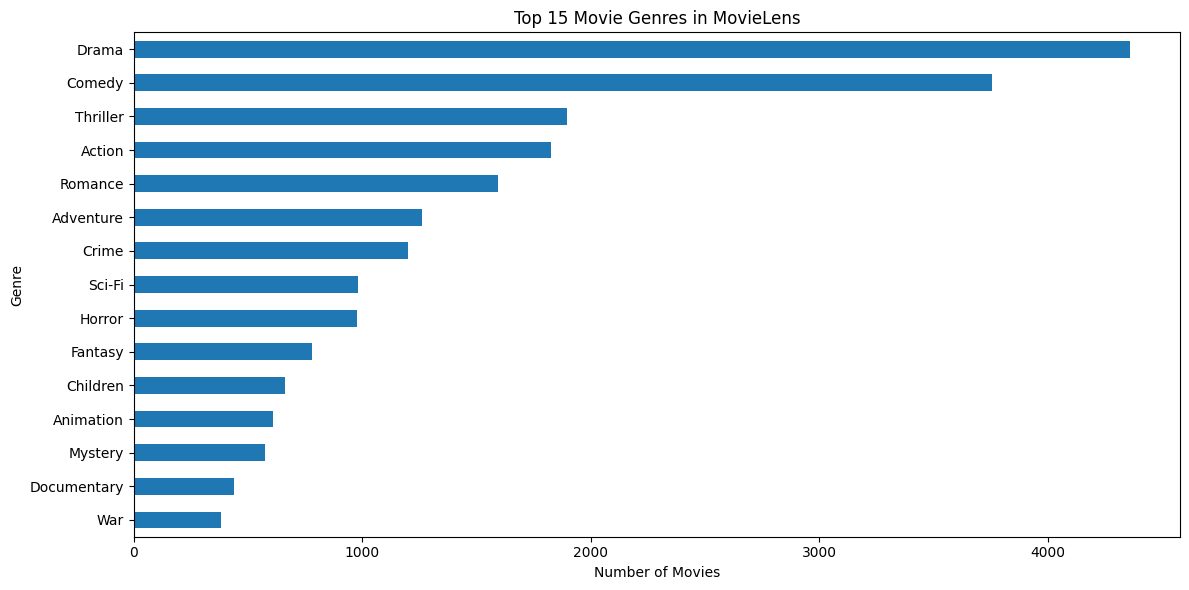

In [10]:
genre_counts = (
    movies["genre_list"]
    .explode()
    .loc[lambda x: x.notna() & (x != "")]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))
genre_counts.sort_values().plot(kind="barh")
plt.title("Top 15 Movie Genres in MovieLens")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [11]:
assert not movies.empty, "Movie dataset is empty!"
assert genre_features.shape[0] == len(movies)
assert genre_features.shape[1] == len(mlb.classes_)

test_result = recommend_movies(
    "Toy Story (1995)",
    n_recommendations=5
)

assert not test_result.empty, "Recommendation test failed!"
assert len(test_result) <= 5

print("All basic validation checks passed.")
print("Movies available:", len(movies))
print("Genres used:", len(mlb.classes_))
print("Recommendations generated:", len(test_result))

All basic validation checks passed.
Movies available: 9742
Genres used: 19
Recommendations generated: 5
